# 04 — Louvain communities of the product graph

Notebook 03 clusters the product graph with spectral clustering, where the number of clusters $k$ has to be chosen. Here the same graph is clustered with our own **Louvain algorithm** (`src/louvain.py`), which maximises modularity directly and decides the number of communities by itself.

1. A toy graph that can be checked by hand, and checks against networkx
2. The product graph (the same graph as notebook 03)
3. Louvain on the product graph and its hierarchy of levels
4. Stability: how much does the result depend on the order of the vertices?
5. The resolution parameter
6. What the communities contain, and how they relate to the real departments and aisles

Needs only `data/derived/rules_support_1e-4.csv` (notebook 02) and `products.csv`, `aisles.csv`, `departments.csv`.

In [45]:
#Requeired imports
import sys, time
from pathlib import Path
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score
sys.path.insert(0, str(Path.cwd().parent))
from src.data import DATA_DIR
from src.louvain import (product_graph, connected_components, subgraph, n_edges, modularity, local_moves, collapse, louvain, community_table)

ROOT = Path.cwd().parent
FIG_DIR, DERIVED = ROOT / 'figures', ROOT / 'data' / 'derived'
FIG_DIR.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', 120)

#Helpers to compare with networkx
def to_networkx(adj):
    G = nx.Graph()
    G.add_nodes_from(range(len(adj)))
    G.add_weighted_edges_from((v, w, weight) for v in range(len(adj)) for w, weight in adj[v].items() if v <= w)
    return G

def as_sets(labels):
    return [set(np.flatnonzero(labels == c).tolist()) for c in np.unique(labels)]

## 1. A toy graph that can be checked by hand

Two triangles joined by one edge ($m = 7$ edges, so $2m = 14$). With the two triangles as communities, each has 3 edges inside (counted in both directions: 6) and a degree sum of 7, so

$$Q = 2\left(\frac{6}{14} - \left(\frac{7}{14}\right)^2\right) = 0.3571$$

**Step 1** (moving single vertices) must find the two triangles. 

**Step 2** must collapse them into two super vertices with a loop of weight $2 \cdot 3 = 6$ each and one edge of weight 1 between them.

The modularity used here includes the terms $v = w$ of the sum, which is the usual definition and the one of networkx.

In [46]:
edges = [(0, 1), (0, 2), (1, 2), (3, 4), (3, 5), (4, 5), (2, 3)]
toy = [{} for _ in range(6)]
for v, w in edges:
    toy[v][w] = toy[w][v] = 1.0

#Step 1
community, improved = local_moves(toy, order=range(6))
print('step 1, community of every vertex:', community)
print(f'modularity: {modularity(toy, community):.4f}')

#Step 2
super_graph, community = collapse(toy, community)
print('step 2, collapsed graph:', super_graph)

#Collapsing must not change the modularity
print('full algorithm:', louvain(toy)[-1])

step 1, community of every vertex: [1, 1, 1, 5, 5, 5]
modularity: 0.3571
step 2, collapsed graph: [{0: 6.0, 1: 1.0}, {1: 6.0, 0: 1.0}]
full algorithm: [0 0 0 1 1 1]


**Check against networkx on a real network.** On Zachary's karate club (unweighted and weighted) our modularity must equal `networkx.community.modularity` for every partition. Louvain itself is a heuristic that depends on the order of the vertices, so the two implementations are compared over 20 orders each: they should reach the same range of modularity, not identical partitions.

In [47]:
K = nx.karate_club_graph()
rows = []
for weight in (None, 'weight'):
    adj_K = [{w: float(d['weight']) if weight else 1.0 for w, d in K[v].items()} for v in range(len(K))]
    ours, theirs = [], []
    for seed in range(20):
        labels = louvain(adj_K, seed=seed)[-1]
        assert np.isclose(modularity(adj_K, labels), nx.community.modularity(K, as_sets(labels), weight=weight))
        ours.append(modularity(adj_K, labels))
        theirs.append(nx.community.modularity(K, nx.community.louvain_communities(K, weight=weight, seed=seed), weight=weight))
    rows.append({'karate club': 'weighted' if weight else 'unweighted', 'ours min': min(ours), 'ours mean': np.mean(ours), 
                 'ours max': max(ours),'networkx min': min(theirs), 'networkx mean': np.mean(theirs), 'networkx max': max(theirs)})
pd.DataFrame(rows).round(4)

,karate club,ours min,ours mean,ours max,networkx min,networkx mean,networkx max
0,unweighted,0.3974,0.4162,0.4198,0.3952,0.4158,0.4198
1,weighted,0.4266,0.4410,0.4449,0.4266,0.4404,0.4449


## 2. The product graph

The same graph as notebook 03, so that the two methods can be compared: one node per product, one edge per frequent pair (support $\ge 10^{-4}$) with lift above 1, weight $\log(\text{lift})$, keeping an edge only if it is among the 10 strongest of one of its two products. The 21 tiny components (2 to 5 products of one brand) are left out and the largest component is clustered.

In [48]:
rules = pd.read_csv(DERIVED / 'rules_support_1e-4.csv')
products = (pd.read_csv(DATA_DIR / 'products.csv').merge(pd.read_csv(DATA_DIR / 'aisles.csv'), on='aisle_id')
            .merge(pd.read_csv(DATA_DIR / 'departments.csv'), on='department_id'))
info = products.set_index('product_id')

#All frequent pairs with lift > 1
adj_all, ids_all = product_graph(rules, top_m=None)
comp = connected_components(adj_all)
print(f'all edges: {len(adj_all):,} products, {n_edges(adj_all):,} edges, {comp.max() + 1} connected components')

#10 strongest edges of every product, largest component
adj_top, ids_top = product_graph(rules, top_m=10)
W, ids = subgraph(adj_top, ids_top, connected_components(adj_top) == 0)
dept = info.loc[ids, 'department'].to_numpy()
aisle = info.loc[ids, 'aisle'].to_numpy()
print(f'chosen graph: {len(W):,} products, {n_edges(W):,} edges,'f'{len(np.unique(dept))} departments and {len(np.unique(aisle))} aisles among them')

all edges: 3,687 products, 54,733 edges, 22 connected components
chosen graph: 3,634 products, 16,583 edges,20 departments and 115 aisles among them


## 3. Louvain on the product graph

Every pass of the algorithm (step 1 + step 2) gives one level of a hierarchy: the communities of a level are merged into the communities of the next one. The table shows the levels of one run, and the same graph clustered by networkx.

In [49]:
t = time.time()
levels = louvain(W, seed=0)
t_ours = time.time() - t

rows = []
for i, labels in enumerate(levels):
    sizes = np.bincount(labels)
    rows.append({'level': i + 1, 'communities': len(sizes), 'modularity': modularity(W, labels),'largest': sizes.max(), 
                 'median size': int(np.median(sizes))})
print(f'our Louvain: {t_ours:.2f} s')
pd.DataFrame(rows).round(4)

our Louvain: 0.06 s


,level,communities,modularity,largest,median size
0,1,251,0.5926,708,3
1,2,72,0.6824,1717,7
2,3,64,0.6854,1722,6


In [50]:
G = to_networkx(W)
t = time.time()
nx_communities = nx.community.louvain_communities(G, weight='weight', seed=0)
t_nx = time.time() - t
print(f'networkx: {len(nx_communities)} communities, modularity {nx.community.modularity(G, nx_communities):.4f}, {t_nx:.2f} s')
print(f'ours:     {len(np.unique(levels[-1]))} communities, modularity {modularity(W, levels[-1]):.4f}, {t_ours:.2f} s')

networkx: 68 communities, modularity 0.6873, 0.18 s
ours:     64 communities, modularity 0.6854, 0.06 s


## 4. Stability

The lecture orders the vertices arbitrarily, and the algorithm can end in a local maximum. We run it with 20 random orders and look at the modularity, the number of communities, and the agreement between every pair of runs (ARI and AMI: 1 for identical partitions, about 0 for unrelated ones).

In [51]:
N_RUNS = 20
runs = [louvain(W, seed=seed)[-1] for seed in range(N_RUNS)]
Q = np.array([modularity(W, labels) for labels in runs])
n_comm = np.array([len(np.unique(labels)) for labels in runs])
pair_ari = [adjusted_rand_score(runs[i], runs[j]) for i in range(N_RUNS) for j in range(i)]
pair_ami = [adjusted_mutual_info_score(runs[i], runs[j]) for i in range(N_RUNS) for j in range(i)]

print(f'modularity:  {Q.min():.4f} to {Q.max():.4f} (mean {Q.mean():.4f}, std {Q.std():.4f})')
print(f'communities: {n_comm.min()} to {n_comm.max()}')
print(f'agreement between two runs: ARI {np.mean(pair_ari):.2f} ({min(pair_ari):.2f} to {max(pair_ari):.2f}),'
      f'AMI {np.mean(pair_ami):.2f} ({min(pair_ami):.2f} to {max(pair_ami):.2f})')

#The run with the highest modularity is used from here on (an unsupervised choice)
best = int(Q.argmax())
labels = runs[best]
print(f'\nkept: run {best} with {n_comm[best]} communities and modularity {Q[best]:.4f}')

modularity:  0.6839 to 0.6901 (mean 0.6867, std 0.0017)
communities: 59 to 74
agreement between two runs: ARI 0.87 (0.51 to 0.98),AMI 0.86 (0.75 to 0.95)

kept: run 2 with 64 communities and modularity 0.6901


The products that change community between runs are not spread evenly. For every product we count how often it shares its community with the same neighbours: the share of its edges that stay inside a community, averaged over the runs.

In [52]:
#Share of each products edge weight that stays inside its community
inside = np.zeros((N_RUNS, len(W)))
for r, run in enumerate(runs):
    for v in range(len(W)):
        inside[r, v] = sum(weight for w, weight in W[v].items() if run[w] == run[v]) / sum(W[v].values())
share = inside.mean(axis=0)
print(f'on average {share.mean():.0%} of a product\'s edge weight is inside its community')
print(f'{(share < 0.5).mean():.0%} of the products have less than half of it inside: these sit between communities')

on average 86% of a product's edge weight is inside its community
8% of the products have less than half of it inside: these sit between communities


## 5. The resolution parameter

Louvain does not take $k$, but modularity can be given a resolution $\gamma$ that multiplies the expected number of edges: $\gamma > 1$ gives more and smaller communities, $\gamma < 1$ fewer and larger ones. It is a one-line change in the gain of step 1. Note that the modularity column below is the usual one ($\gamma = 1$) so that the rows are comparable.

In [53]:
rows = []
for gamma in (0.25, 0.5, 1, 2, 4, 8):
    lab = louvain(W, gamma=gamma, seed=best)[-1]
    rows.append({'gamma': gamma, 'communities': len(np.unique(lab)), 'modularity': modularity(W, lab), 'largest': np.bincount(lab).max(),
                 'AMI dept': adjusted_mutual_info_score(dept, lab), 'AMI aisle': adjusted_mutual_info_score(aisle, lab)})
pd.DataFrame(rows).round(3)

,gamma,communities,modularity,largest,AMI dept,AMI aisle
0,0.25,51,0.508,2979,0.133,0.113
1,0.50,37,0.637,1607,0.120,0.120
2,1.00,64,0.690,1720,0.161,0.165
3,2.00,91,0.663,815,0.175,0.186
4,4.00,130,0.606,702,0.182,0.200
5,8.00,181,0.566,698,0.191,0.205


## 6. Communities and the real categories

AMI (adjusted mutual information) is used as in notebook 03: 0 for random labels, 1 for identical partitions. A random permutation of our labels is scored too. If notebook 03 has been run, its spectral clusters are compared on the same products.

In [54]:
def score(name, lab):
    return {'method': name, 'clusters': len(np.unique(lab)), 'modularity': modularity(W, lab), 'largest cluster': np.bincount(lab).max(),
            'AMI dept': adjusted_mutual_info_score(dept, lab), 'AMI aisle': adjusted_mutual_info_score(aisle, lab),
            'ARI dept': adjusted_rand_score(dept, lab), 'ARI aisle': adjusted_rand_score(aisle, lab)}

nx_labels = np.zeros(len(W), dtype=int)
for c, members in enumerate(nx_communities):
    nx_labels[list(members)] = c

rng = np.random.default_rng(0)
results = [score('Louvain (own)', labels), score('Louvain (networkx)', nx_labels), score('random labels', rng.permutation(labels))]

spectral_file = DERIVED / 'spectral_clusters_k50.csv'
if spectral_file.exists():
    spectral = pd.read_csv(spectral_file).set_index('product_id').loc[ids, 'cluster'].to_numpy()
    results.append(score('spectral, k = 50 (notebook 03)', spectral))
    print(f'Louvain vs spectral: ARI {adjusted_rand_score(labels, spectral):.3f}, AMI {adjusted_mutual_info_score(labels, spectral):.3f}')
else:
    print('spectral_clusters_k50.csv not found: run notebook 03 to add the spectral row')

pd.DataFrame(results).round(3)

Louvain vs spectral: ARI 0.359, AMI 0.611


,method,clusters,modularity,largest cluster,AMI dept,AMI aisle,ARI dept,ARI aisle
0,Louvain (own),64,0.690,1720,0.161,0.165,0.002,0.004
1,Louvain (networkx),68,0.687,1662,0.155,0.163,0.005,0.005
2,random labels,64,-0.003,1720,0.002,0.000,-0.001,0.001
3,"spectral, k = 50 (notebook 03)",50,0.590,711,0.137,0.144,0.023,0.023


In [55]:
table = pd.DataFrame(community_table(labels, ids, info, W))
print(f'{(table["size"] >= 10).sum()} of {len(table)} communities have at least 10 products')
table.head(12)

20 of 64 communities have at least 10 products


,community,size,top department,top aisle,purity (dept),examples
0,1,1720,dairy eggs (16%),chips pretzels (4%),0.159884,Banana; Organic Strawberries; Bag of Organic Bananas; Organic Hass Avocado; Organic Baby Spinach
1,4,421,produce (34%),fresh vegetables (21%),0.337292,Organic Garlic; Organic Yellow Onion; Organic Zucchini; Organic Italian Parsley Bunch; Organic Cilantro
2,7,364,dairy eggs (24%),fresh fruits (12%),0.244505,Organic Whole String Cheese; Original Hummus; Apple Honeycrisp Organic; Uncured Genoa Salami; Organic Sticks Low Moi...
3,3,338,produce (34%),fresh vegetables (18%),0.340237,Strawberries; Cucumber Kirby; Yellow Onions; 2% Reduced Fat Milk; 100% Whole Wheat Bread
4,6,147,produce (37%),packaged produce (15%),0.374150,Clementines; Trail Mix; Hass Avocados; Soda; 0% Greek Strained Yogurt
5,2,68,beverages (54%),water seltzer sparkling water (37%),0.544118,Sparkling Water Grapefruit; Passionfruit Sparkling Water; Lime Sparkling Water; Kiwi Sandia Sparkling Water; Curate ...
6,10,61,dairy eggs (39%),frozen produce (34%),0.393443,Frozen Organic Wild Blueberries; Organic Unsweetened Almond Milk; Organic Whole Strawberries; Pineapple Chunks; Orga...
7,0,59,beverages (80%),refrigerated (39%),0.796610,Organic Raw Kombucha Gingerade; Trilogy Kombucha Drink; Organic & Raw Strawberry Serenity Kombucha; Synergy Organic ...
8,24,48,snacks (29%),energy granola bars (29%),0.291667,Crunchy Peanut Butter Energy Bar; Blueberry Crisp Energy Bar; Chocolate Brownie Energy Bar; White Chocolate Macadami...
9,23,44,babies (98%),baby food formula (98%),0.977273,Baby Food Stage 2 Blueberry Pear & Purple Carrot; Spinach Peas & Pear Stage 2 Baby Food; Organic Stage 4 Green Bean ...


In [56]:
print('The purest communities (by department share, at least 10 products):')
table[table['size'] >= 10].sort_values('purity (dept)', ascending=False).head(10)

The purest communities (by department share, at least 10 products):


,community,size,top department,top aisle,purity (dept),examples
10,15,25,dairy eggs (100%),yogurt (92%),1.000000,Total 2% with Strawberry Lowfat Greek Strained Yogurt; Total 2% Lowfat Greek Strained Yogurt With Blueberry; Blackbe...
13,9,16,dairy eggs (100%),yogurt (100%),1.000000,Peach on the Bottom Nonfat Greek Yogurt; Raspberry on the Bottom Nonfat Greek Yogurt; Blueberry on the Bottom Nonfat...
18,31,11,beverages (100%),water seltzer sparkling water (91%),1.000000,Unsweetened Watermelon Water; Raspberry Essence Water; Unsweet Peach Water; Unsweetened Blackberry Water; Unsweetene...
16,44,13,dairy eggs (100%),yogurt (100%),1.000000,Lemon Yogurt; Coconut Yoghurt; Raspberry Yoghurt; Tart Cherry Yoghurt; Peach Yoghurt
15,20,13,snacks (100%),energy granola bars (100%),1.000000,Lemon Fruit & Nut Food Bar; Apple Pie Fruit & Nut Food Bar; Blueberry Muffin Bar; Coconut Cream Pie; Cherry Pie Frui...
14,8,13,frozen (100%),frozen meals (100%),1.000000,Pesto Tortellini Bowls; Broccoli & Cheddar Bake Meal Bowl; Macaroni & Cheese; Organic Beans & Rice Cheddar Cheese B...
19,19,10,frozen (100%),ice cream ice (100%),1.000000,Chocolate Ice Cream; Mint Chip; Birthday Cake Light Ice Cream; Strawberry Ice Cream; Lemon Cake Ice Cream
9,23,44,babies (98%),baby food formula (98%),0.977273,Baby Food Stage 2 Blueberry Pear & Purple Carrot; Spinach Peas & Pear Stage 2 Baby Food; Organic Stage 4 Green Bean ...
7,0,59,beverages (80%),refrigerated (39%),0.796610,Organic Raw Kombucha Gingerade; Trilogy Kombucha Drink; Organic & Raw Strawberry Serenity Kombucha; Synergy Organic ...
17,58,12,snacks (75%),energy granola bars (75%),0.750000,Chocolate Sea Salt; Coconut Chocolate Bar; Coconut Chia Bar; Chocolate Peanut Butter; Acai Berry Chia Bar


**Communities vs. departments.** Each column is a community (largest on the left, first 30 shown); each cell is the share of that community's products from the department in that row.

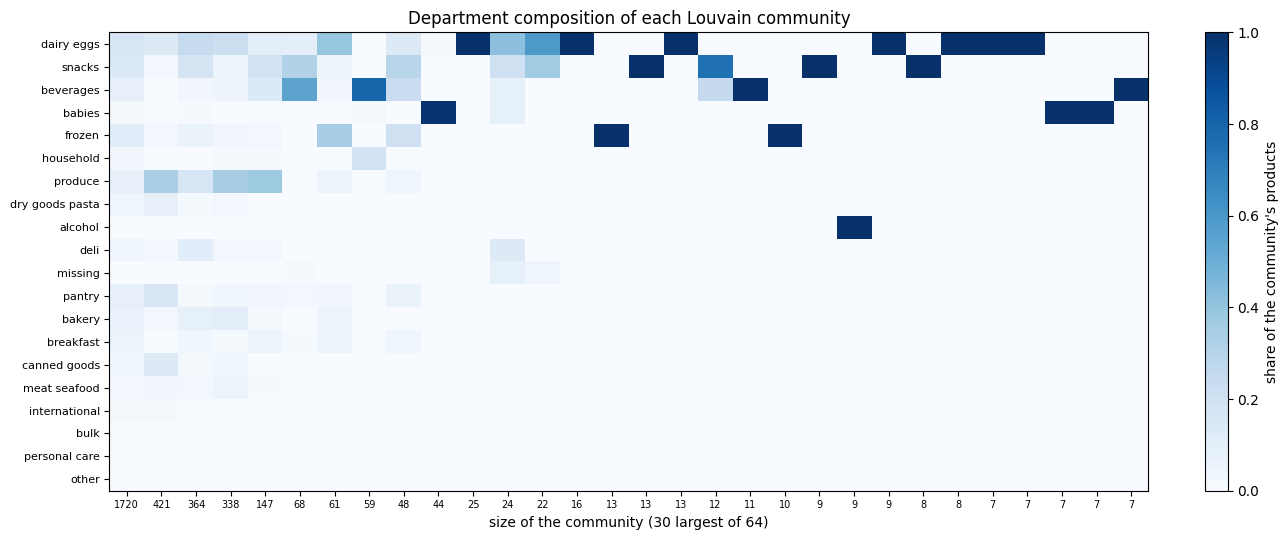

In [57]:
shown = 30
order = table['community'].to_numpy()[:shown]
cross = pd.crosstab(pd.Series(dept, name='department'), pd.Series(labels, name='community'), normalize='columns')
cross = cross.loc[cross.sum(axis=1).sort_values(ascending=False).index, order]

fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(cross.to_numpy(), cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set_yticks(range(len(cross)), cross.index, fontsize=8)
ax.set_xticks(range(shown), table['size'].to_numpy()[:shown], fontsize=7)
ax.set(xlabel=f'size of the community (30 largest of {len(table)})', title='Department composition of each Louvain community')
fig.colorbar(im, ax=ax, label="share of the community's products", fraction=0.025)
fig.tight_layout()
fig.savefig(FIG_DIR / 'louvain_communities_vs_departments.png', dpi=150)

In [58]:
out = pd.DataFrame({'product_id': ids, 'community': labels})
out.to_csv(DERIVED / 'louvain_communities.csv', index=False)
print(f'saved {len(out):,} products with their community to data/derived/louvain_communities.csv')

saved 3,634 products with their community to data/derived/louvain_communities.csv


## Conclusions

- **Correctness.** On the toy graph step 1 finds the two tirangles with the modularity computed by hand (0.3571) and step 2 gives the collapsed graph of the lecture (loops of 6, one edge of 1) without changing the modularity. Our modularity equals networkx's on every partition tested, and on the karate club our Louvain reaches the same range of modularity as networkx's over 20 vertex orders (maximum 0.4198 unweighted, 0.4449 weighted, for both).
- **Result.** On the product graph (3,634 products, 16,583 edges) Louvain needs 3 passes and about 0.1 s: 251 communities after the first pass, then 72, then 64, with modularity 0.59, 0.68 and 0.69. This is well above the 0.3 that indicates community structure, above the best spectral clustering of notebook 03 (0.59 at $k = 50$), and the same as networkx (0.687 with 68 communities).
- **No $k$ needed, but one giant community.** Louvain chooses the number of communities itself, but almost half of the products (about 1,720) end in one community around the most popular products (bananas, strawberries, avocados), and only 20 of the 64 communities have at least 10 products. Modularity prefers to merge groups that are small compared with the whole graph (its resolution limit), and everyday groceries are bought with everything.
- **Stability.** Over 20 vertex orders the modularity barely changes (0.684 to 0.690) but the partition does: 59 to 74 communities and a mean ARI of 0.87 between two runs (lowest 0.51). Many different partitions have almost the same modularity. About 8% of the products have less than half of their edge weight inside their community; these are the ones that move.
- **Resolution.** A larger $\gamma$ splits the giant community (largest community 815 products at $\gamma = 2$, about 700 at $\gamma = 4$) and raises the agreement with aisles a little (AMI from 0.17 to 0.19 and 0.20), at the cost of a lower modularity.
- **Purchase behaviour vs. the store layout.** The agreement with the real categories is weak but clearly not random: AMI 0.16 for departments and 0.17 for aisles, against 0.00 for shuffled labels, slightly above spectral clustering (about 0.14). ARI is close to 0 because it is dominated by the giant community. As in notebook 03, the communities are product lines and shopping missions and not departments: single-brand yogurt flavours, ice cream, sparkling waters, energy bars, baby food and kombucha are almost pure, while the large communities mix produce, dairy and snacks.